# NLP Task 1

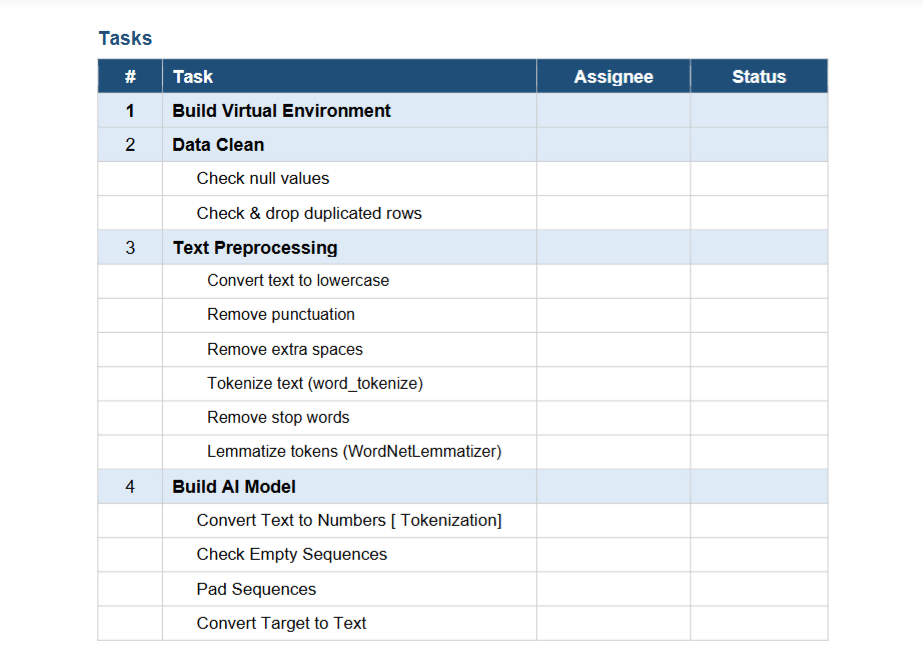

# 1. Build Virtual Environment

 create Virtual Environment using conda 
 

In [9]:
# Create a new conda environment for NLP tasks
#conda create --name nlp_tasks 

In [11]:
# Activate the NLP tasks environment
#conda activate nlp_tasks

## Setup 

In [ ]:
#!pip install pandas
#!pip install numpy
#!pip install matplotlib
#!pip install nltk



#!pip install tensorflow
#!pip install google

In [12]:
import  pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import string


import nltk
from nltk.tokenize import word_tokenize

## - Data

In [13]:
df = pd.read_csv("Dataset/train.csv")
df.sample(15)

,id,keyword,location,text,target
3745,5322,fire,NaN,My asshole is on fire https://t.co/Y3FO0gHg8t,0
2437,3500,derailed,"Arlington, VA and DC",@GerryConnolly @RepDonBeyer @timkaine Today's ...,1
492,713,attacked,NaN,Christian Attacked by Muslims at the Temple Mo...,1
2340,3367,demolition,Chicago,Saving the City in Old Town: The Proposed Demo...,1
2484,3567,desolate,NaN,If the Taken movies took place in India 2 (Vin...,0
1009,1464,body%20bagging,NaN,@MzGracieBaby for the record im jumpin out the...,0
3149,4523,emergency,We are global!,SF Asian Women's Shelter crisis line (415) 751...,1
2086,2998,dead,NaN,@AtchisonSean he is dead,0
2151,3086,deaths,Blackpool,Cancers equate for around 25% of all deaths in...,1
4005,5688,floods,"Ogba, Lagos, Nigeria",APC Chieftain Tasks Dickson On N15b Floods Don...,1


In [14]:
#from google.colab import sheets
#sheet = sheets.InteractiveSheet(df=df)

#2. Data Clean

Check null values

In [15]:
df.isnull().sum()

id             0
keyword       61
location    2533
text           0
target         0
dtype: int64

## Fill null values With NAN (thoses not important)

In [17]:
df.fillna("NAN", inplace=True)

,id,keyword,location,text,target
0,1,NAN,NAN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NAN,NAN,Forest fire near La Ronge Sask. Canada,1
2,5,NAN,NAN,All residents asked to 'shelter in place' are ...,1
3,6,NAN,NAN,"13,000 people receive #wildfires evacuation or...",1
4,7,NAN,NAN,Just got sent this photo from Ruby #Alaska as ...,1
...,...,...,...,...,...
7608,10869,NAN,NAN,Two giant cranes holding a bridge collapse int...,1
7609,10870,NAN,NAN,@aria_ahrary @TheTawniest The out of control w...,1
7610,10871,NAN,NAN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1
7611,10872,NAN,NAN,Police investigating after an e-bike collided ...,1


## Check again after filling

In [18]:
df.isnull().sum()

id          0
keyword     0
location    0
text        0
target      0
dtype: int64

Check & drop duplicated rows

In [19]:
df.duplicated().sum()

np.int64(0)

### Check if there is same tweet (duplicated tweets)?

In [20]:
df.duplicated('text').sum()

np.int64(110)

### Show all duplicated tweets

In [21]:
#duplicated_df = df[df.duplicated('text', keep=False)].sort_values(by='text')
#sheet = sheets.InteractiveSheet(df=duplicated_df)

### Remove Duplicates

In [22]:
resolved_targets = (
    df.groupby('text')['target']
    .mean()
    .apply(lambda mean_val: 1 if mean_val >= 0.5 else 0)
)
df['target'] = df['text'].map(resolved_targets)
df.drop_duplicates(subset=['text'], keep='first', inplace=True)
df.reset_index(drop=True, inplace=True)

In [23]:
df.duplicated('text').sum()

np.int64(0)

In [24]:
df.shape

(7503, 5)

#3. Text Preprocessing

Convert text to lowercase

In [25]:
df['text'] = df['text'].str.lower()

In [26]:
df['text'].sample(15)

3189    #healthcare #job in #kodiak ak: emergency serv...
4859    breaking: authorities respond to ocean fire ht...
6599                   my mama scared of the thunder ????
6160    i liked a @youtube video http://t.co/z8cp77lvz...
1557     fall off a cliff please  https://t.co/4vwsl2gfp0
7178    richard returns after whirlwind few days http:...
6092                        @ik4len sirens was cancelled.
1638    and he almost collapsed bc he said his wish ca...
6200    todayûªs storm will pass; let tomorrowûªs li...
4192    apocalpytic iran heat wave nearly breaks world...
6453    by the grace of god i survived the 2am shift a...
5852    @arianagrande i literally walked out of the co...
3046    why does my phone electrocute me when it's cha...
7104    'education is the most powerful weapon which y...
3807    @flames_nation that's the optimistic side of m...
Name: text, dtype: str

Remove punctuation

In [27]:
table = str.maketrans('', '', string.punctuation)

# Apply translation directly to the 'text' column
df['text'] = df['text'].astype(str).str.translate(table)
df['text'].sample(15)

4071    if youre gonna take a break at work you gotta ...
3081    i was blow drying my hair amp the cable caught...
6040    lol j2bone cousin  foxysiren coursing weyreygi...
6389    one direction is taking a break after this nex...
5984    rt twitsandiego possible sinkhole disrupts tro...
7240    photos the rocky fire has grown into californi...
2920    janiethekillr jack closed the sketchbook bitin...
2261    yea so im gonna demolish all those boundaries ...
840     that horrible moment when u open up the dryer ...
1402    afghanistan sharp rise in women and children c...
6022    that horrible sinking feeling when youûªve be...
2476      the abomination that maketh desolate the ant...
7151    in memory of the victims of hiroshima and naga...
7313    love is the weapon for this wounded generation...
2597    putin decree results in destruction of 10 tons...
Name: text, dtype: str

Remove extra spaces

In [28]:
df['text'] = df['text'].astype(str).apply(lambda x: ' '.join(x.split()))
df['text'].head(15)

0     our deeds are the reason of this earthquake ma...
1                 forest fire near la ronge sask canada
2     all residents asked to shelter in place are be...
3     13000 people receive wildfires evacuation orde...
4     just got sent this photo from ruby alaska as s...
5     rockyfire update california hwy 20 closed in b...
6     flood disaster heavy rain causes flash floodin...
7     im on top of the hill and i can see a fire in ...
8     theres an emergency evacuation happening now i...
9      im afraid that the tornado is coming to our area
10          three people died from the heat wave so far
11    haha south tampa is getting flooded hah wait a...
12    raining flooding florida tampabay tampa 18 or ...
13                flood in bago myanmar we arrived bago
14    damage to school bus on 80 in multi car crash ...
Name: text, dtype: str

Tokenize text (word_tokenize)

In [29]:

nltk.download('punkt')
nltk.download('punkt_tab')


df['text'] = df['text'].astype(str).apply(word_tokenize)


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\loq\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\loq\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [33]:
df['text'].sample(15)

5326    [panicking, maybe, bff, left, china, bar, mayb...
3119    [eye, nation, amp, broader, conservation, comm...
7193    [brothernlaw, riooooos, got, call, head, north...
3096    [whistleblower, lawsuit, accuses, supervisor, ...
3511    [russian, food, crematorium, provoke, outrage,...
4987    [course, one, day, dress, professionally, aka,...
1427    [best, special, report, metric, correlate, bes...
725     [jannet2208, fell, someone, back, hit, head, c...
3362    [whether, like, everything, come, dark, ready,...
2910     [got, drowned, like, 5, time, damn, game, today]
4263    [swansea, plot, hijack, transfer, move, southa...
5406    [reddit, quarantine, offensive, content, reddi...
866     [wind, take, gypsy, blood, time, httptco66yvul...
5560    [recap, 12000, nigerian, refugee, repatriated,...
4854    [iûªve, seen, lot, ask, mt, jmcwrites, pitchw...
Name: text, dtype: object

Remove stop words

In [30]:
from nltk.corpus import stopwords
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\loq\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [31]:
stop_words = set(stopwords.words('english'))

df['text'] = df['text'].apply(
    lambda tokens: [word for word in tokens if word.lower() not in stop_words]
)

df['text'].sample(15)

4709    [tianta, breaking, news, unconfirmed, heard, l...
542      [snowflake, avalanche, ever, feels, responsible]
5366    [brandonmulcahy, fpine, heres, story, httptcot...
6960    [save, upset, stress, upheaval, let, us, help,...
953     [check, ameribag, healthy, back, bag, shoulder...
793         [dotish, blight, car, go, right, ahead, mine]
4895    [3, titan, warriorcord, 100, feet, authentic, ...
1698    [2, cars, right, front, collided, hadnt, stopp...
3632                              [chrisman528, fatality]
5863                           [bizzlemahomie, screaming]
1991    [wonderousallure, crosses, arms, cover, hands,...
2839    [californians, like, living, africas, sahel, d...
3986    [california, fires, rage, forest, service, sou...
6044    [whelen, model, 295ss100, siren, amplifier, po...
1122                           [wasp, dive, bombed, face]
Name: text, dtype: object

Lemmatize tokens (WordNetLemmatizer)

---



In [32]:
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet')
nltk.download('omw-1.4')

lemmatizer = WordNetLemmatizer()

df['text'] = df['text'].apply(
    lambda tokens: [lemmatizer.lemmatize(word) for word in tokens]
)



[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\loq\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\loq\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [34]:
df['text'].sample(15)

3237    [tanzania, elephant, population, declined, 60,...
696     [let, hot, blazing, fantasy, escort, gfe, duba...
4663    [wish, earth, sea, sky, would, send, someone, ...
6855    [tsunami, dvbbs, amp, borgeous, arceen, festiv...
1985    [trillion, cross, line, 3rd, time, fieldwide, ...
6627    [falling, asleep, sound, thousand, river, plat...
2290    [got, first, gamer, troll, demolished, kid, ph...
2901    [visting, georgina, drowned, rat, cafeawful, v...
591     [thank, fedex, longer, shipping, live, microbe...
4353    [susanj357, msnbc, allinwithchris, like, watch...
182     [ambulance, sprinter, automatic, frontline, ve...
4783    [friend, really, friend, theyd, support, regar...
3092    [elsa, gon, na, end, getting, electrocuted, sh...
4706    [shawie17shawie, breaking, news, unconfirmed, ...
6939    [obama, declares, disaster, typhoondevastated,...
Name: text, dtype: object

#4. Build AI Model

Convert Text to Numbers [ Tokenization ]

In [35]:
from tensorflow.keras.preprocessing.text import Tokenizer

# Initialize the Tokenizer
tokenizer = Tokenizer(oov_token='<OOV>')

# Fit on the list of lemmatized tokens
tokenizer.fit_on_texts(df['text'])

# Convert text to sequences of integers
df['sequences'] = tokenizer.texts_to_sequences(df['text'])

# Print vocabulary size and sample output
print(f'Vocabulary Size: {len(tokenizer.word_index)}')
display(df[['text', 'sequences']].head(5))

Vocabulary Size: 21280


,text,sequences
0,"[deed, reason, earthquake, may, allah, forgive...","[4072, 446, 162, 68, 1699, 4073, 7]"
1,"[forest, fire, near, la, ronge, sask, canada]","[106, 2, 163, 519, 6092, 6093, 1064]"
2,"[resident, asked, shelter, place, notified, of...","[1541, 1410, 1889, 471, 6094, 317, 191, 1889, ..."
3,"[13000, people, receive, wildfire, evacuation,...","[2569, 11, 4074, 76, 191, 379, 34]"
4,"[got, sent, photo, ruby, alaska, smoke, wildfi...","[32, 1065, 113, 6095, 1700, 185, 76, 6096, 102]"


In [36]:
df.sample(15)

,id,keyword,location,text,target,sequences
4796,6945,massacre,NAN,"[afk10, drjohanfranzen, isi, orchs, dont, abil...",1,"[16135, 16136, 415, 16137, 13, 2619, 350, 821,..."
4965,7194,mudslide,NAN,"[nikistitz, even, one, looked, like, mudslide]",0,"[16478, 117, 10, 1999, 3, 331]"
34,52,ablaze,"Philadelphia, PA","[cry, set, ablaze]",0,"[802, 166, 525]"
56,81,ablaze,"Sao Paulo, Brazil","[set, heart, ablaze, every, city, gift, every,...",0,"[166, 285, 525, 137, 107, 2167, 137, 4090, 3, ..."
4468,6461,injured,NAN,"[cant, believe, blevins, got, injured, falling...",1,"[53, 530, 15422, 32, 179, 1032, 3896, 141, 423..."
3456,5002,explosion,New York,"[new, explosionproof, tempered, glass, screen,...",0,"[8, 2504, 2505, 1113, 1537, 2506, 771, 2507, 2..."
457,665,attack,Bellevue NE,"[new, post, darkreading, httptco8eijdxapnp, ne...",1,"[8, 208, 6939, 6940, 8, 6941, 6942, 47, 3270, ..."
722,1052,bleeding,NAN,"[cute, dinner, date, til, cam, nose, start, bl...",0,"[1983, 2720, 1019, 3343, 2721, 1982, 306, 365]"
4590,6637,inundation,NAN,"[oh, boot, amp, heart, social, medium, inundat...",0,"[364, 2533, 4, 285, 1375, 509, 1693, 1824, 100]"
2814,4096,displaced,"Na:tinixw / Hoopa, Berkeley","[elem, pomo, helping, displaced, rocky, fire, ...",1,"[5154, 11911, 1214, 513, 1370, 2, 100, 2448, 5..."


In [37]:
df.shape

(7503, 6)

Check Empty Sequences

In [38]:
empty_seqs_count = df['sequences'].apply(lambda x: len(x) == 0).sum()
print(f'Number of empty sequences: {empty_seqs_count}')

if empty_seqs_count > 0:
    display(df[df['sequences'].apply(lambda x: len(x) == 0)].head())

Number of empty sequences: 0


Pad Sequences

In [39]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Calculate sequence lengths
seq_lengths = df['sequences'].apply(len)
max_len = int(np.percentile(seq_lengths, 95))
print(f'95th percentile of sequence lengths (selected max_len): {max_len}')

# Pad sequences
X = pad_sequences(df['sequences'], maxlen=max_len, padding='post', truncating='post')
print(f'Shape of input tensor X: {X.shape}')

95th percentile of sequence lengths (selected max_len): 16
Shape of input tensor X: (7503, 16)


Convert Target to Text

In [40]:
# Extract the target labels
y = df['target'].values
print(f'Shape of target array y: {y.shape}')
print(f'Target class distribution:\n{df["target"].value_counts()}')

Shape of target array y: (7503,)
Target class distribution:
target
0    4302
1    3201
Name: count, dtype: int64
